# Onboarding demo: from raw data to a structured and automated DataJoint pipeline

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SCENE-Collaboration/SCENE-pipelines/blob/dev/examples/tutorials/02_scene_onboarding_demo.ipynb)

This notebook covers a basic example of all the steps to onboard your lab with the SCENE datajoint pipelines. 
Starting with raw example data, all the way to an automated DataJoint pipeline. We use the shared tables (`Session`, `VideoRecording`, `dlc.Pose`, …), and put some lab's own tables on top. 

**Code**
The code product of this tutorial is packaged in [`scene_onboarding_demo`](https://github.com/SCENE-Collaboration/SCENE-pipelines/tree/dev/examples/tutorials/scene_onboarding_demo), next to this
notebook. In this notebook we walk through the steps how to arrive there.

If you are new to DataJoint and to the SCENE-pipelines repository, we recommend to first run the [Getting started](01_getting_started.ipynb) notebook for the basics of the shared tables.


**Before you start** (on Colab, the first code cell does all of this)

- Install the package with its DeepLabCut and video extras, from the repository root:
  `pip install -e ".[dlc,video]" matplotlib`
- Start the local MySQL database: `make init` once, then `make db_up`
- Run this notebook from `examples/tutorials/`, so that `tutorial_utils` and `scene_onboarding_demo` can be
  imported

Everything is written to databases named `tutorial_onboarding_*`. Every step can run again.

In [1]:
# On Google Colab only: a local MySQL server, the package and this folder. Elsewhere this cell does nothing.
import os
import sys

SCENE_REF = "dev"  # the branch or tag of SCENE-pipelines to install

if "google.colab" in sys.modules:
    !apt-get -qq update > /dev/null && apt-get -qq install -y mysql-server > /dev/null
    !service mysql start
    !mysql -u root -e "ALTER USER 'root'@'localhost' IDENTIFIED WITH mysql_native_password BY 'tutorial'"
    !pip install -q "scene-pipelines[dlc,video] @ git+https://github.com/SCENE-Collaboration/SCENE-pipelines.git@{SCENE_REF}"
    !git clone -q --depth 1 -b {SCENE_REF} https://github.com/SCENE-Collaboration/SCENE-pipelines.git /content/SCENE-pipelines
    %cd /content/SCENE-pipelines/examples/tutorials
    os.environ["DJ_PASS"] = "tutorial"

## The data

This notebook uses basic representative example data of what your behavioral data could look like: a set of video recordings, session files (`sessions/`), and a DeepLabCut project.


The example data is one zip of about 54 MB. This cell downloads it and unpacks it into `scene_onboarding_data/`, next to this notebook; It can also be manually downloaded from the repository via [this link](https://github.com/SCENE-Collaboration/SCENE-pipelines/releases/download/tutorial-data/scene-onboarding-demo-data-v1.zip). 


- Already have the zip? Put it next to this notebook, and the cell only unpacks it..
- Stopped halfway? Delete `scene_onboarding_data/` and run the cell again.

**Layout**
```bat
scene_onboarding_data/                          next to the notebook: the unpacked data zip
├── sessions/
│   ├── mice.json                               the lab's mice: name, sex, birth date, strain
│   └── <mouse>_<YYYY-MM-DD>_<attempt>/         one folder per session, named by its code
│       ├── <mouse>_<YYYY-MM-DD>_<attempt>.json  the transfer GUI's file: details + welfare
│       └── recording.json                      the tracked video: camera, video, poses, arena
├── active_sensing_ephys-celia-2026-06-26/      the DeepLabCut project, offline video and poses
└── live/                                       the live recordings, poses and frame times
```

**Acknowledgements**

The mouse *DemoTuatara* and every metadata value in the data's `sessions/` folder are made up for
this demo. The recordings and DeepLabCut results are real data from unpublished neural recordings in the AR task.
If you use this data, please cite

> Benquet, C., Sainsbury, T., Bruneau, L., et al., & Mathis, M. W. (2026). Visual uncertainty and task demands shape active sensing strategies in mice. *Current Biology*, *36*(14), 3523–3534.e9. [https://doi.org/10.1016/j.cub.2026.06.011](https://doi.org/10.1016/j.cub.2026.06.011)

In [1]:
import shutil
import urllib.request
from pathlib import Path

URL = "https://github.com/SCENE-Collaboration/SCENE-pipelines/releases/download/tutorial-data/scene-onboarding-demo-data-v1.zip"
ZIP = Path("scene-onboarding-demo-data-v1.zip")
DATA = Path("scene_onboarding_data").resolve()  # next to this notebook; change it for another copy

if not DATA.exists():
    if not ZIP.exists():
        urllib.request.urlretrieve(URL, ZIP)
    shutil.unpack_archive(ZIP, DATA)

# Print the unpacked files and directories
print("\n".join(path.name for path in DATA.iterdir()))

active_sensing_ephys-celia-2026-06-26
live
README.md
sessions


## Setup demo databases and connect

This section sets up local databases for the tutorial. Normally, this process is already taken
care of for your lab, before you start ingesting data for your experiments. Each lab has a contact person that will
set this up together with the SCENE Data Science Core.

Connecting to the central simons server will be made easier using single-sign-on.

In [ ]:
import datajoint as dj
import tutorial_utils

# Connect to the DataJoint service
SCHEMA_PREFIX = "tutorial_onboarding_"
tutorial_utils.connect(prefix=SCHEMA_PREFIX)

c:\Users\Jaap\miniconda\envs\human\Lib\site-packages\datajoint\settings.py:1052: UserWarning: No datajoint.json found. Using defaults and environment variables. Run `dj.config.save_template()` to create a template configuration.
  config = _create_config()


127.0.0.1:3310, schemas prefixed 'tutorial_onboarding_'


SCENE is built from DataJoint schemas: groups of related tables, such as video, dlc and the lab's own. A lab uses only the schemas it needs. Importing a schema's module declares its tables in Python. Activating the schema then creates those tables in the database, if they don't exist yet, and binds the Python classes to them, so you can read and write through them.

In [ ]:
import scene_pipelines.ingestion.dlc  # noqa: F401
import scene_pipelines.ingestion.mouse  # noqa: F401
import scene_pipelines.ingestion.video  # noqa: F401
from scene_pipelines.core import SCENE_REGISTRY

import scene_onboarding_demo.schemas  # noqa: F401

SCENE_REGISTRY.activate_all()

## The lab's codes

`scene_onboarding_demo/admin.py` holds the lab's codes: the lab, its project,
and a code for each experimenter and each DeepLabCut project.

Codes in the shared tables are seen by the whole consortium, so they must not name anyone. The GUI
records an experimenter's name, and DeepLabCut names a project folder after its labeller; the lab's
code replaces both.

In [ ]:
from scene_onboarding_demo import admin

print("lab:     ", admin.LAB)
print("project: ", admin.PROJECT)
print("experimenters:      ", admin.EXPERIMENTER_CODES)
print("DeepLabCut projects:", admin.DLC_PROJECT_CODES)

Once per lab, an admin registers the lab, its project, and its experimenters' codes, with the
helpers of `scene_pipelines.ingestion`:

In [ ]:
from scene_pipelines.ingestion.provenance import DuplicatePolicy
from scene_pipelines.ingestion.scene.admin import ensure_lab, ensure_project
from scene_pipelines.schemas.scene.session import Experimenter

from scene_onboarding_demo.admin import EXPERIMENTER_CODES, LAB, LAB_KEY, PROJECT

ensure_lab(LAB, if_exists=DuplicatePolicy.VERIFY)
ensure_project(PROJECT, if_exists=DuplicatePolicy.VERIFY)
for code in EXPERIMENTER_CODES.values():
    Experimenter.insert1({**LAB_KEY, "experimenter_code": code}, skip_duplicates=True)

## One automated call: `ingest()`

Subject → Session → video and poses → computed results, for one session folder:

In [ ]:
from tutorial_utils import display_code

from scene_onboarding_demo.register import ingest

display_code(ingest)

## Step by step

### 1. Validated data discovery in Python

In [ ]:
import pandas as pd

from scene_onboarding_demo.manifest import discover_sessions, read_session_folder

# Discover all the sessions on disk
sessions = discover_sessions(DATA / "sessions")
for folder in sessions:
    print(folder.name)

FIRST, SECOND = sessions

# Inspect a specific session
manifest = read_session_folder(FIRST)
pd.Series(manifest.session.model_dump(), name=manifest.session.session_code).to_frame()

A wrong field fails here, by name, and nothing is written. Uncomment to try:

In [ ]:
from scene_onboarding_demo.manifest import SessionEntry, gui_file, read_json

broken = {**read_json(gui_file(FIRST)), "weight_percentage": "heavy", "rig": 2}

SessionEntry(**broken)

## 2. Ingesting into the database

### 2a. The SCENE shared layer

The mouse and the session, written with the helpers of `scene_pipelines.ingestion`. The lab's
code replaces the experimenter's name.

In [ ]:
from scene_pipelines.ingestion import register_session
from scene_pipelines.ingestion.mouse import ensure_strain, register_mouse
from scene_pipelines.schemas.mouse.mouse import Mouse
from scene_pipelines.schemas.scene.session import Session
from scene_pipelines.schemas.scene.subject import Subject

from scene_onboarding_demo.admin import EXPERIMENTER_CODES, PROJECT_KEY

mouse = register_mouse(
    manifest.mouse.mouse_name,
    manifest.mouse.sex,
    lab=LAB_KEY,
    date_of_birth=manifest.mouse.date_of_birth,
    strain=ensure_strain({"strain_name": manifest.mouse.strain}),
    genotype=manifest.mouse.genotype or None,
)
session = register_session(
    manifest.session.session_code,
    manifest.session.session_date,
    lab=LAB_KEY,
    subjects=[mouse],
    project=PROJECT_KEY,
    experimenter={
        **LAB_KEY,
        "experimenter_code": EXPERIMENTER_CODES[manifest.session.experimenter_name],
    },
)

display((Subject * Mouse & mouse).proj("subject_code", "sex", "date_of_birth", "strain_name"))
Session & session

The DeepLabCut project, in the shared `dlc` schema: `DlcProject` under the lab's code, and
`ProjectConfig`, one row per version of its `config.yaml`, with the keypoints and the likelihood threshold
(`pcutoff`). The file itself is not uploaded: SCENE records its hash.

The project's labelled frames (`CollectedData_*.h5`) are not in the shared schema yet, so this version of
the demo does not register them.

In [ ]:
from scene_pipelines.ingestion.dlc import register_dlc_project, register_project_config
from scene_pipelines.schemas.dlc.project import DlcProject, ProjectConfig

from scene_onboarding_demo.admin import DLC_PROJECT_CODES

dlc_folder = manifest.recording.dlc_project
project = register_dlc_project(
    DLC_PROJECT_CODES[dlc_folder.name], lab=LAB_KEY, scene_project=PROJECT_KEY
)
config = register_project_config(DATA / dlc_folder / "config.yaml", dlc_project=project)

display(DlcProject & project)
(ProjectConfig & config).proj("task", "pcutoff") * ProjectConfig.Bodypart

### 2b. The recording: shared video and poses

The session's video goes to `video.VideoRecording` (its take, and the video's fps, size and frame
count), and its DeepLabCut poses to `dlc.Pose`, one row per keypoint in `Pose.Keypoint`. Both are
shared tables, written with the helpers of `scene_pipelines.ingestion`. This first session has no
frame times; for the live session in step 4, `ingest` also passes the recorder's and DLC-live's.

In [ ]:
from scene_pipelines.ingestion.dlc import register_pose
from scene_pipelines.ingestion.video import register_video_recording
from scene_pipelines.schemas.dlc.pose import Pose
from scene_pipelines.schemas.video.recording import VideoRecording
from scene_pipelines.schemas.video.video import VideoFile

rec = manifest.recording
video = register_video_recording(DATA / rec.video, session=session, take=rec.take)
pose = register_pose(
    DATA / rec.poses,
    dlc_project=project,
    video={"file_sha256": (VideoRecording & video).fetch1("file_sha256")},
)

display((VideoRecording * VideoFile & video).proj("fps", "width", "height", "n_frames"))
Pose & pose

### 2c. The lab layer: the lab's own tables

What only this lab records goes to its own tables, on top of the shared rows: the session's details
and welfare check (`SessionInfo`, `ScoreSheet`), and the `Recording` that ties the video to its
poses, the arena, and where the arena's corners are in the image. These two helpers are in
`scene_onboarding_demo/register.py`:

In [ ]:
from scene_onboarding_demo.register import register_recording, register_session_details
from scene_onboarding_demo.schemas import Recording, ScoreSheet, SessionInfo

display_code(register_session_details)
display_code(register_recording)

In [ ]:
register_session_details(manifest.session, session=session)
recording = register_recording(rec, video=video, pose=pose, config=config)

display(SessionInfo * ScoreSheet & session)
(Recording & recording).proj("arena_name", "video_path")

### 3. Computed for you

In [18]:
from scene_onboarding_demo.schemas import Kinematics, Trajectory

Trajectory.populate()
Kinematics.populate()

Kinematics & recording

session_id,lab_id,camera_code,take,duration_s,distance_cm,mean_speed_cm_s,moving_fraction,center_fraction
7e34c4a6-68b3-4b8b-ab29-a61b59cff5a0,demo,top,1,29.99,294.75,9.68727,0.489,0.598333


The path from the `Trajectory` table, on a video frame warped to a top-down view of the 52 × 52 cm arena;
the dashed square is its central quarter.

In [ ]:
import matplotlib.pyplot as plt

from scene_onboarding_demo.plots import plot_path

fig, ax = plt.subplots(figsize=(6.5, 5))
plot_path(ax, recording, data=DATA)
ax.set_title(manifest.session.session_code, fontsize=10);

---
## 4. The next session? One call

Months later the same mouse is tracked live with DeepLabCut-live. Everything the steps above did by hand,
`ingest` does for its folder. The mouse and the DeepLabCut project are recognised, not written again.

{'session_id': UUID('dd59ce24-db7b-4d59-9dcf-2b3aa7a972b7')}

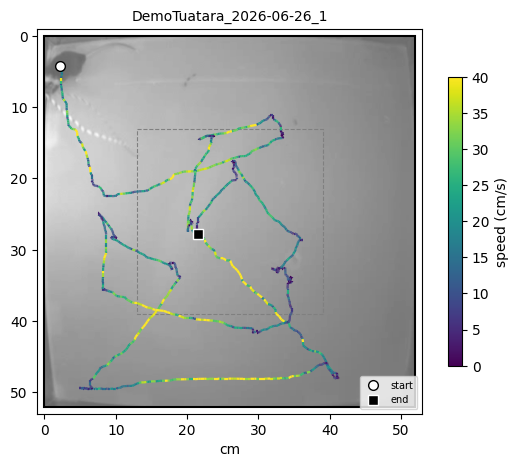

In [20]:
ingest(SECOND)

In [ ]:
keys = (Recording * Session).keys(order_by="session_date")
fig, axes = plt.subplots(1, len(keys), figsize=(6 * len(keys), 5))
for ax, key in zip(axes, keys):
    plot_path(ax, key, data=DATA, colorbar=ax is axes[-1])
    session_code = (Session & key).fetch1("session_code")
    scorer = (Pose & Recording().pose(key)).fetch1("scorer")
    ax.set_title(f"{session_code} ({'live' if scorer == 'DLC_live' else 'offline'})", fontsize=10)
fig.tight_layout()

Anyone with access to the database gets the same from a query, without the lab's disks: per session, the
mouse's age, its weight change at the welfare check, and how it explored. (The live session lasts 7 s
against 30 s offline, so compare with care.)

In [22]:
per_session = (
    Session * Session.Subject * Subject * Mouse * ScoreSheet * Recording * Kinematics
).proj(
    "subject_code",
    "session_date",
    "weight_percentage",
    "distance_cm",
    "mean_speed_cm_s",
    "center_fraction",
    age_days="DATEDIFF(session_date, date_of_birth)",
)
columns = [
    "subject_code",
    "age_days",
    "session_date",
    "weight_percentage",
    "distance_cm",
    "mean_speed_cm_s",
    "center_fraction",
]
per_session.to_pandas().reset_index()[columns].round(2)

,subject_code,age_days,session_date,weight_percentage,distance_cm,mean_speed_cm_s,center_fraction
0,DemoTuatara,106,2026-06-26,-2.5,294.75,9.69,0.6
1,DemoTuatara,236,2026-11-03,1.0,46.50,6.78,0.0


## 5. How the lab's own tables are written

The lab's tables are in
**[`schemas/behavior.py`](https://github.com/SCENE-Collaboration/SCENE-pipelines/blob/dev/examples/tutorials/scene_onboarding_demo/schemas/behavior.py)**.
They reference the shared `VideoRecording`, `dlc.Pose` and `dlc.ProjectConfig`; nothing in scene-pipelines
changes.

```text
Session ─> VideoRecording ─┐
dlc.Pose ──────────────────┼──> Recording ──> Trajectory ──> Kinematics
dlc.ProjectConfig, Arena ──┘    (Manual)      (Computed)     (Computed)
```

Look at `Kinematics`: a `definition` (what is stored per key) and a `make(key)` that reads its upstream
rows and inserts one row. That pair is all `populate()` needs to fill exactly what is missing, for this
session or the next hundred. `Trajectory.make` reads the poses back with
`scene_pipelines.ingestion.dlc.keypoint`, one keypoint at a time.

## Start over

Drops every table under this notebook's prefix; restart the kernel afterwards. Uncomment to run.

In [4]:
from tutorial_utils import drop_tutorial_schemas

drop_tutorial_schemas(SCHEMA_PREFIX)

['tutorial_onboarding_behavior',
 'tutorial_onboarding_dlc',
 'tutorial_onboarding_files',
 'tutorial_onboarding_lab',
 'tutorial_onboarding_mouse',
 'tutorial_onboarding_provenance',
 'tutorial_onboarding_scene',
 'tutorial_onboarding_video']